# Polynomial Linear Regression

In [6]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import r2_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


In [ ]:
# Making a non-linear data

x = 6 * np.random.rand(200, 1) - 3
y = (0.8 * x**2) + (0.9 * x) + (2) + (np.random.randn(200, 1))

# y_cap = 0.8x^2 + 0.9x + 2

Text(0, 0.5, 'Output y')

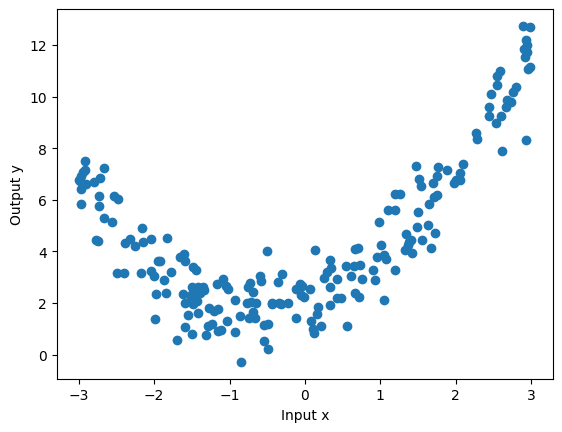

In [19]:
plt.scatter(x, y)
plt.xlabel('Input x')
plt.ylabel('Output y')

In [ ]:
# Train Test split

x_train, x_test, y_train, y_test = train_test_split(x, y, random_state = 1)

# Applying Linear Regression
lr = LinearRegression()

# Training the model
lr.fit(x_train, y_train)

# Predicting x_test
y_pred = lr.predict(x_test) 

# Finding r_2 score
r2 = r2_score(y_test, y_pred)

print(r2)

0.39227847109496505


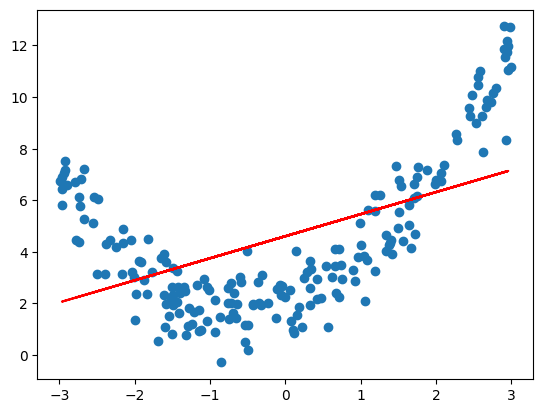

In [23]:
# Plotting the line

plt.scatter(x, y)
plt.plot(x_test, y_pred, color = 'red')

# Applying Polynomial Linear Regression

In [50]:
poly = PolynomialFeatures(degree = 2, include_bias = True)

x_train_poly = poly.fit_transform(x_train)
x_test_poly = poly.fit_transform(x_test)


print(f"""
{x_train_poly[0:5]}

{'-'*20} x_poly {'-'*20}
{x_test_poly[0:5]}""")

# We got columns x^0, x^1 and x^2


[[ 1.         -1.34972238  1.82175051]
 [ 1.          0.21716665  0.04716135]
 [ 1.          2.53232149  6.41265211]
 [ 1.         -1.41186056  1.99335023]
 [ 1.         -1.69634591  2.87758943]]

-------------------- x_poly --------------------
[[ 1.          0.98658719  0.97335429]
 [ 1.          2.95295423  8.71993867]
 [ 1.          2.06092499  4.24741181]
 [ 1.          2.93065336  8.58872914]
 [ 1.         -0.4934124   0.24345579]]


In [62]:
# Training Linear Regression on Polynomial Features
lr.fit(x_train_trans, y_train)

# Predicting x_test_trans
y_pred_poly = lr.predict(x_test_trans)

# Calculating r2_score
r2_poly = r2_score(y_test, y_pred_trans)

print(f"R2 Score (Poly) -> {r2_poly}")

print(f'''
Coeffecients: {lr.coef_}
Intercept: {lr.intercept_}''')

# See, our R2_Score increased for Polynomial Features

R2 Score (Poly) -> 0.876213582472155

Coeffecients: [[0.         0.92368165 0.8302644 ]]
Intercept: [2.01921837]


C:\Users\jugal\AppData\Local\Temp\ipykernel_5320\1974294021.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


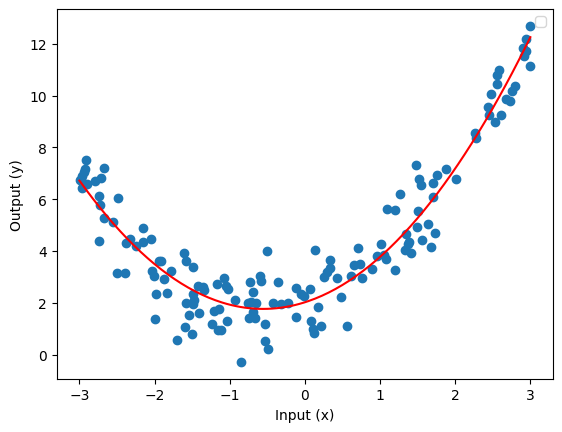

In [70]:
# Plotting the line by adjusting sizes

# Generating some other values of x for making predicting
x_new=np.linspace(-3, 3, 200).reshape(200, 1)

# Getting polynomial features of x
x_new_poly = poly.transform(x_new)

# Predicting x
y_new = lr.predict(x_new_poly)

plt.scatter(x_train, y_train)
plt.plot(x_new, y_new, color = 'red')
plt.xlabel("Input (x)")
plt.ylabel("Output (y)")
plt.legend()
plt.show()

# Impact of degree on regression line

* Change the degree and notice the line.
* If we set the degree very low, the model will start to underfit.    
* If we set the degree very high, the model will start to overfitt. It will literally try to byheart the data by capturing all the points

In [86]:
def polynomial_regression(degree):
    x_new=np.linspace(-3, 3, 100).reshape(100, 1)
    # x_new_poly = poly.transform(x_new)

    polybig_features = PolynomialFeatures(degree=degree, include_bias=False)
    std_scaler = StandardScaler()
    lin_reg = LinearRegression()
    polynomial_regression = Pipeline([
            ("poly_features", polybig_features),
            ("std_scaler", std_scaler),
            ("lin_reg", lin_reg),
        ])
    polynomial_regression.fit(x, y)
    y_newbig = polynomial_regression.predict(x_new)
    plt.plot(x_new, y_newbig,'r', label="Degree " + str(degree), linewidth=2)

    plt.plot(x_train, y_train, "b.", linewidth=3)
    plt.plot(x_test, y_test, "g.", linewidth=3)
    plt.legend(loc="upper left")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.axis([-3, 3, 0, 10])
    plt.show()

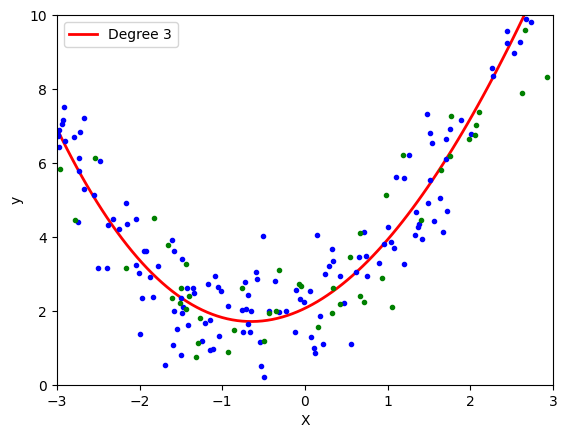

In [87]:
polynomial_regression(degree = 3)